In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('/Users/sachinchoudhary/Developer/ML/data/iris.csv')
df.head()

,sepal_length,sepal_width,petal_length,petal_width,class
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


In [3]:
from sklearn.preprocessing import LabelEncoder
encoder = LabelEncoder()

In [4]:
df['class'] = encoder.fit_transform(df['class'])

In [5]:
df.head()

,sepal_length,sepal_width,petal_length,petal_width,class
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


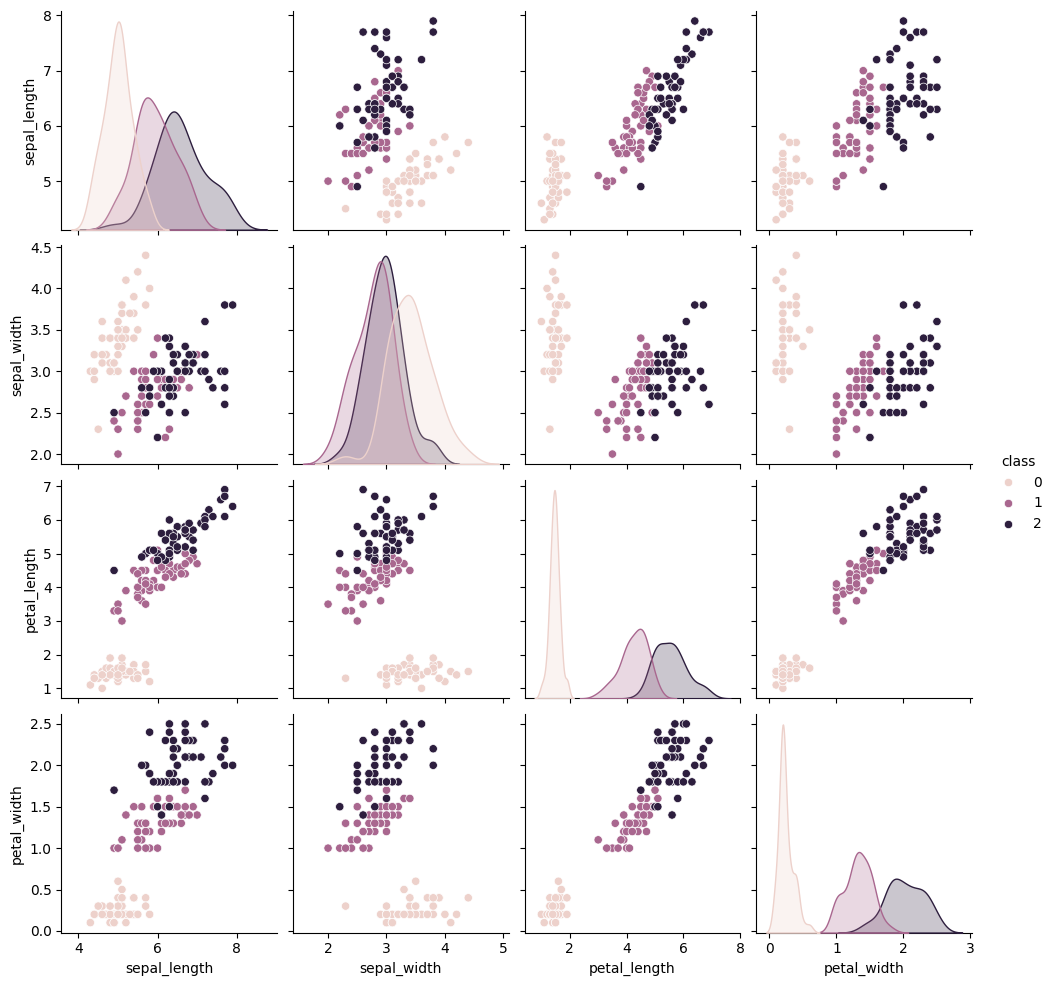

In [6]:
import seaborn as sns
sns.pairplot(df, hue='class')

In [7]:
new_df = df[df['class'] != 0][['sepal_length','sepal_width','class']]

In [8]:
new_df.head()

,sepal_length,sepal_width,class
50,7.0,3.2,1
51,6.4,3.2,1
52,6.9,3.1,1
53,5.5,2.3,1
54,6.5,2.8,1


In [9]:
X = new_df.iloc[:,:2]
y = new_df.iloc[:,-1]

In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score

In [11]:
clf1 = LogisticRegression()
clf2 = KNeighborsClassifier()
clf3 = RandomForestClassifier()

In [12]:
estimators = [('lr',clf1),('knn',clf2),('rf',clf3)]

In [13]:
for estimator in estimators:
    x = cross_val_score(estimator[1],X,y,scoring='accuracy',cv=10)
    print(estimator[0],"->",np.round(np.mean(x),2))

lr -> 0.75
knn -> 0.59
rf -> 0.61


In [14]:
from sklearn.ensemble import VotingClassifier

In [15]:
vc = VotingClassifier(estimators=estimators)
x = cross_val_score(vc,X,y,scoring='accuracy',cv=10)
print(np.round(np.mean(x),2))

0.67


In [16]:
vc = VotingClassifier(estimators=estimators,voting='soft')
x = cross_val_score(vc,X,y,scoring='accuracy',cv=10)
print(np.round(np.mean(x),2))

0.66


In [17]:
for i in range(1,4):
    for j in range(1,4):
        for k in range(1,4):
            vc = VotingClassifier(estimators=estimators,voting='soft',weights=[i,j,k])
            x = cross_val_score(vc,X,y,scoring='accuracy',cv=10)
            print("for i={}, j={}, k={} ->".format(i,j,k),np.round(np.mean(x),2))

for i=1, j=1, k=1 -> 0.66
for i=1, j=1, k=2 -> 0.63
for i=1, j=1, k=3 -> 0.6
for i=1, j=2, k=1 -> 0.66
for i=1, j=2, k=2 -> 0.63
for i=1, j=2, k=3 -> 0.62
for i=1, j=3, k=1 -> 0.64
for i=1, j=3, k=2 -> 0.63
for i=1, j=3, k=3 -> 0.61
for i=2, j=1, k=1 -> 0.69
for i=2, j=1, k=2 -> 0.66
for i=2, j=1, k=3 -> 0.64
for i=2, j=2, k=1 -> 0.65
for i=2, j=2, k=2 -> 0.64
for i=2, j=2, k=3 -> 0.63
for i=2, j=3, k=1 -> 0.67
for i=2, j=3, k=2 -> 0.66
for i=2, j=3, k=3 -> 0.64
for i=3, j=1, k=1 -> 0.7
for i=3, j=1, k=2 -> 0.69
for i=3, j=1, k=3 -> 0.66
for i=3, j=2, k=1 -> 0.69
for i=3, j=2, k=2 -> 0.68
for i=3, j=2, k=3 -> 0.66
for i=3, j=3, k=1 -> 0.7
for i=3, j=3, k=2 -> 0.65
for i=3, j=3, k=3 -> 0.65


In [18]:
from sklearn.datasets import make_classification
from sklearn.svm import SVC

X, y = make_classification(n_samples=1000, n_features=20, n_informative=15, n_redundant=5, random_state=2)

svm1 = SVC(probability=True, kernel='poly', degree=1)
svm2 = SVC(probability=True, kernel='poly', degree=2)
svm3 = SVC(probability=True, kernel='poly', degree=3)
svm4 = SVC(probability=True, kernel='poly', degree=4)
svm5 = SVC(probability=True, kernel='poly', degree=5)

In [19]:
estimators = [('svm1',svm1),('svm2',svm2),('svm3',svm3),('svm4',svm4),('svm5',svm5)]

for estimator in estimators:
    x = cross_val_score(estimator[1],X,y,scoring='accuracy',cv=10)
    print(estimator[0],"->",np.round(np.mean(x),2))

svm1 -> 0.85
svm2 -> 0.85
svm3 -> 0.89
svm4 -> 0.81
svm5 -> 0.86


In [20]:
vc = VotingClassifier(estimators=estimators,voting='soft')
x = cross_val_score(vc,X,y,scoring='accuracy',cv=10)
print(np.round(np.mean(x),2))

0.93
